# PHAROS CDR: Notebook 01 - Dataset Exploration & Data Quality Audit

This notebook performs the initial exploratory data analysis (EDA) and data quality audit on the raw extracted feature matrix (`dataset.csv`).

### Exploration Goals:
1. **Dataset Dimensions & Integrity**: Inspect row/column dimensionality, schema typing, and identifier integrity (`sha256`).
2. **Target Balance**: Quantify distribution of Benign ($0$) vs. Malicious ($1$) samples.
3. **Missing Value Audit**: Quantify feature sparsity and evaluate missingness patterns across format classes.
4. **Variability & Redundancy Screening**: Screen for zero-variance constant features and duplicate feature vectors.
5. **Statistical Distribution**: Analyze feature skewness, variance levels, and binary indicator density.
6. **Preliminary Bivariate Correlation**: Screen preliminary label correlations and flag potential data leakage tokens.

## 1. Environment Setup & Data Ingestion
Loading core analytics libraries and ingesting the full feature matrix extracted by the static feature extraction pipeline.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)

print("Libraries loaded.")

Libraries loaded.


In [2]:
df = pd.read_csv("/content/dataset.csv")

## 2. Shape, Schema & Identifier Verification
Inspecting the matrix dimensionality, verifying sample uniqueness via SHA256 hashes, and confirming ground truth label presence.

In [3]:
print("Shape:", df.shape)

print("\nColumns:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes.value_counts())

print("\nFirst 5 rows:")
display(df.head())

Shape: (2330, 1000)

Columns:
['sha256', 'label', 'behavior_collection.collection_category_clipboard_access', 'behavior_collection.collection_category_clipboard_access_count', 'behavior_collection.collection_category_count', 'behavior_collection.collection_category_input_capture', 'behavior_collection.collection_category_input_capture_count', 'behavior_collection.collection_category_local_collection', 'behavior_collection.collection_category_local_collection_count', 'behavior_collection.collection_category_media_capture', 'behavior_collection.collection_category_media_capture_count', 'behavior_collection.collection_category_screen_capture', 'behavior_collection.collection_category_screen_capture_count', 'behavior_collection.collection_evidence_count', 'behavior_collection.collection_indicator_audio_capture', 'behavior_collection.collection_indicator_audio_capture_count', 'behavior_collection.collection_indicator_clipboard', 'behavior_collection.collection_indicator_clipboard_count', 'b

,sha256,label,behavior_collection.collection_category_clipboard_access,behavior_collection.collection_category_clipboard_access_count,behavior_collection.collection_category_count,behavior_collection.collection_category_input_capture,behavior_collection.collection_category_input_capture_count,behavior_collection.collection_category_local_collection,behavior_collection.collection_category_local_collection_count,behavior_collection.collection_category_media_capture,behavior_collection.collection_category_media_capture_count,behavior_collection.collection_category_screen_capture,behavior_collection.collection_category_screen_capture_count,behavior_collection.collection_evidence_count,behavior_collection.collection_indicator_audio_capture,behavior_collection.collection_indicator_audio_capture_count,behavior_collection.collection_indicator_clipboard,behavior_collection.collection_indicator_clipboard_count,behavior_collection.collection_indicator_count,behavior_collection.collection_indicator_file_search,behavior_collection.collection_indicator_file_search_count,behavior_collection.collection_indicator_keylogging,behavior_collection.collection_indicator_keylogging_count,behavior_collection.collection_indicator_screen_capture,behavior_collection.collection_indicator_screen_capture_count,behavior_collection.collection_indicator_webcam_capture,behavior_collection.collection_indicator_webcam_capture_count,behavior_collection.collection_indicator_window_text,behavior_collection.collection_indicator_window_text_count,behavior_collection.collection_source_size,behavior_credentials.credential_category_browser_credentials,behavior_credentials.credential_category_browser_credentials_count,behavior_credentials.credential_category_count,behavior_credentials.credential_category_generic_search,behavior_credentials.credential_category_generic_search_count,behavior_credentials.credential_category_manager_credentials,behavior_credentials.credential_category_manager_credentials_count,behavior_credentials.credential_category_os_credentials,behavior_credentials.credential_category_os_credentials_count,behavior_credentials.credential_category_token_manipulation,behavior_credentials.credential_category_token_manipulation_count,behavior_credentials.credential_category_tool_indicators,behavior_credentials.credential_category_tool_indicators_count,behavior_credentials.credential_evidence_count,behavior_credentials.credential_indicator_browser_credentials,behavior_credentials.credential_indicator_browser_credentials_count,behavior_credentials.credential_indicator_count,behavior_credentials.credential_indicator_credential_manager,behavior_credentials.credential_indicator_credential_manager_count,behavior_credentials.credential_indicator_lsass_access,...,vba_execution.vba_execution_indicator_auto_open,vba_execution.vba_execution_indicator_auto_open_count,vba_execution.vba_execution_indicator_callbyname,vba_execution.vba_execution_indicator_callbyname_count,vba_execution.vba_execution_indicator_createobject,vba_execution.vba_execution_indicator_createobject_count,vba_execution.vba_execution_indicator_eval_call,vba_execution.vba_execution_indicator_eval_call_count,vba_execution.vba_execution_indicator_execute_call,vba_execution.vba_execution_indicator_execute_call_count,vba_execution.vba_execution_indicator_execute_global_call,vba_execution.vba_execution_indicator_execute_global_call_count,vba_execution.vba_execution_indicator_getobject,vba_execution.vba_execution_indicator_getobject_count,vba_execution.vba_execution_indicator_ontime,vba_execution.vba_execution_indicator_ontime_count,vba_execution.vba_execution_indicator_sendkeys,vba_execution.vba_execution_indicator_sendkeys_count,vba_execution.vba_execution_indicator_shell_call,vba_execution.vba_execution_indicator_shell_call_count,vba_execution.vba_execution_indicator_sleep,vba_execution.vba_execution_indicator_sleep_count,vba_execution.vba_execution_indicator_wscript_shell_run,vba_execution.vba_execution_ind

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2330 entries, 0 to 2329
Columns: 1000 entries, sha256 to vba_obfuscation.vba_obfuscation_string_manipulation_count
dtypes: float64(998), int64(1), object(1)
memory usage: 17.8+ MB


In [5]:
print("SHA256 column exists:", "sha256" in df.columns)
print("Label column exists:", "label" in df.columns)

feature_columns = [
    c for c in df.columns
    if c not in ["sha256", "label"]
]

print("Number of features:", len(feature_columns))

SHA256 column exists: True
Label column exists: True
Number of features: 998


In [9]:
print("Total rows:", len(df))
print("Unique SHA256:", df["sha256"].nunique())
print("Duplicate SHA256:", df["sha256"].duplicated().sum())

Total rows: 2330
Unique SHA256: 2330
Duplicate SHA256: 0


In [10]:
X = df.drop(columns=["sha256", "label"])

duplicate_vectors = X.duplicated().sum()

print("Duplicate feature vectors:", duplicate_vectors)

Duplicate feature vectors: 0


> [!NOTE]
> **Inference on Dimensionality & Integrity**:
> The raw feature matrix contains exactly **2,330 distinct files** across **1,000 columns** (998 extracted feature columns, 1 identifier `sha256`, and 1 binary `label`). Every sample has a unique SHA-256 hash with 0 duplicate feature vectors, confirming that the sample ingestion and hash indexing operate with high integrity.

## 3. Class Balance & Target Distribution
Auditing class representation to ensure balanced evaluation and avoid majority-class optimization bias.

In [6]:
print(df["label"].value_counts())

label
1    1183
0    1147
Name: count, dtype: int64


In [7]:
label_counts = df["label"].value_counts()

print(
    (label_counts / len(df) * 100)
    .round(2)
)

label
1    50.77
0    49.23
Name: count, dtype: float64


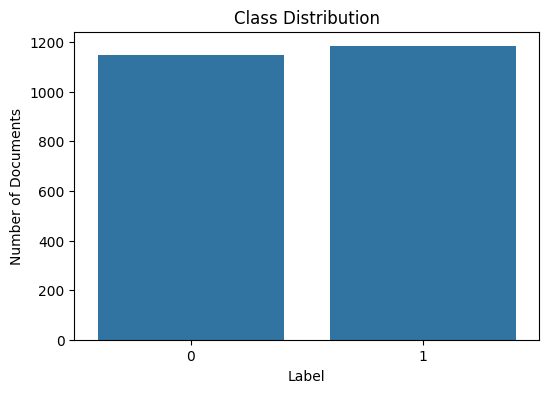

In [8]:
plt.figure(figsize=(6, 4))

sns.countplot(
    data=df,
    x="label"
)

plt.title("Class Distribution")
plt.xlabel("Label")
plt.ylabel("Number of Documents")
plt.show()

> [!TIP]
> **Inference on Class Balance**:
> The dataset is remarkably balanced: **1,183 malicious files (50.77%)** and **1,147 benign files (49.23%)**. Standard stratified sampling without synthetic oversampling (such as SMOTE) is well-suited for subsequent training, preserving natural feature distributions.

## 4. Sparsity & Missing Value Analysis
Quantifying missingness across all extracted features to determine whether missing values represent data loss or format-specific absence.

In [11]:
missing = df.isna().sum()

missing = (
    missing[missing > 0]
    .sort_values(ascending=False)
)

print("Features containing missing values:", len(missing))
display(missing.head(30))

Features containing missing values: 12


,0
ooxml.ooxml_content_types_macro_override_count,168
ooxml.ooxml_content_types_macro_enabled,166
ooxml.ooxml_content_types_override_count,166
ooxml.ooxml_content_types_present,166
ooxml.ooxml_document_paragraphs,166
ooxml.ooxml_document_text_characters,166
ooxml.ooxml_document_xml_present,166
ooxml.ooxml_relationships_attached_templates,166
ooxml.ooxml_relationships_external,166
ooxml.ooxml_relationships_hyperlinks,166


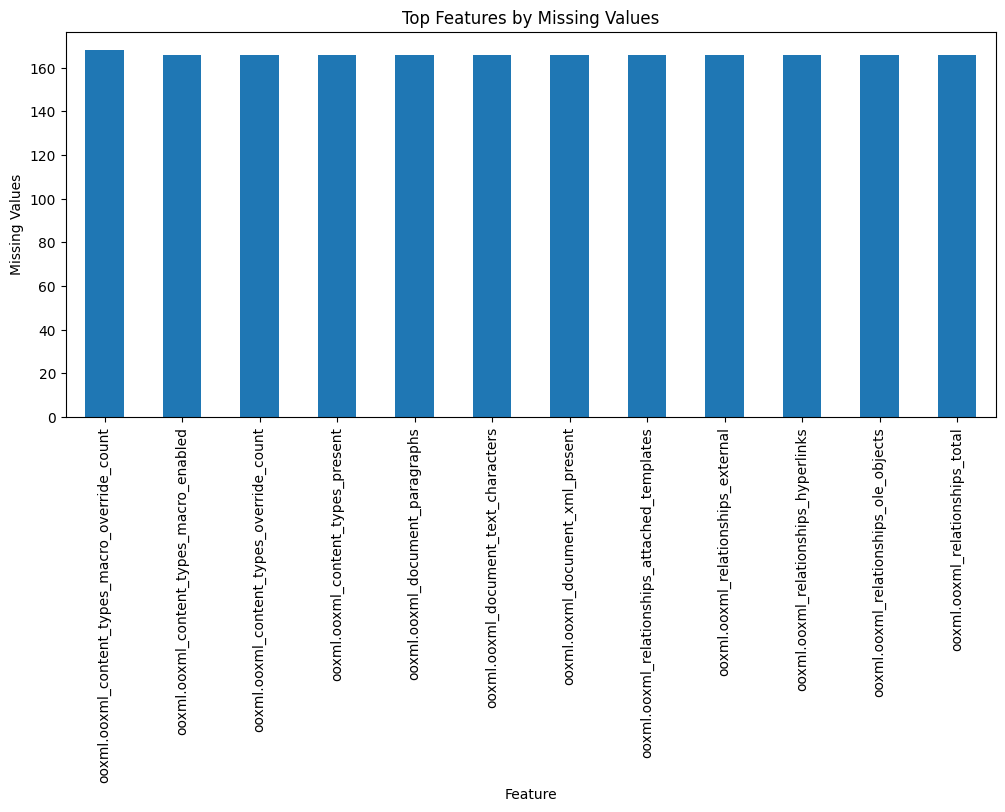

In [12]:
plt.figure(figsize=(12, 5))

missing.head(30).plot(kind="bar")

plt.title("Top Features by Missing Values")
plt.xlabel("Feature")
plt.ylabel("Missing Values")
plt.xticks(rotation=90)
plt.show()

In [13]:
total_missing = df.isna().sum().sum()

print("Total missing values:", total_missing)
print(
    f"Missing-value percentage: "
    f"{total_missing / df.size * 100:.4f}%"
)

Total missing values: 1994
Missing-value percentage: 0.0856%


> [!NOTE]
> **Inference on Missingness**:
> Missing values are exceptionally sparse—only **12 of 998 features** contain missing entries, totaling **1,994 missing cells (0.0856% of the entire matrix)**. Missingness is strictly confined to OOXML package attributes (e.g., text character counts, paragraph counts, external relationships) which naturally evaluate to `NaN` when analyzing non-OOXML files (flat scripts, RTF, raw text). Median or zero imputation is appropriate for these columns.

## 5. Constant & Duplicate Column Audit
Identifying non-informative feature columns that contribute zero variance or duplicate information.

In [14]:
X = df.drop(columns=["sha256", "label"])

nunique = X.nunique(dropna=False)

constant_features = nunique[nunique <= 1]

print("Constant features:", len(constant_features))
display(constant_features)

Constant features: 783


,0
behavior_collection.collection_category_clipboard_access,1
behavior_collection.collection_category_clipboard_access_count,1
behavior_collection.collection_category_count,1
behavior_collection.collection_category_input_capture,1
behavior_collection.collection_category_input_capture_count,1
...,...
vba_obfuscation.vba_obfuscation_indicator_numeric_character_construction_count,1
vba_obfuscation.vba_obfuscation_indicator_repeated_numeric_character_sequence,1
vba_obfuscation.vba_obfuscation_indicator_repeated_numeric_character_sequence_count,1
vba_obfuscation.vba_obfuscation_string_manipulation,1


In [15]:
print(
    f"{len(constant_features) / X.shape[1] * 100:.2f}% "
    "of features are constant."
)

78.46% of features are constant.


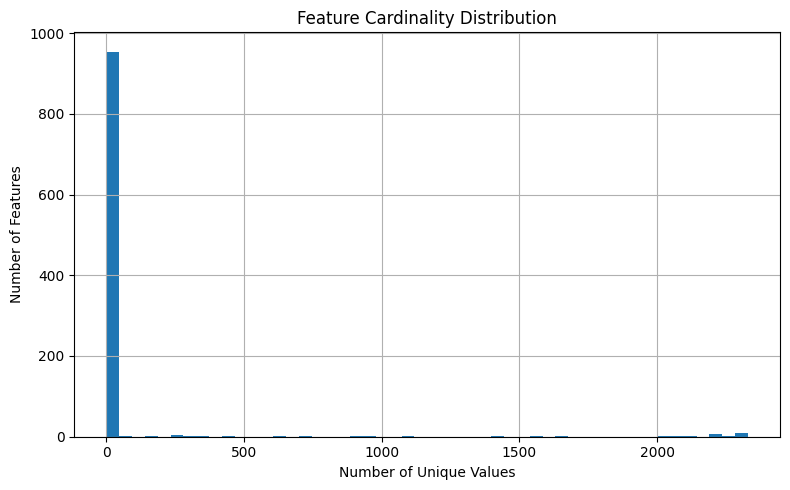

In [17]:
cardinality = df.nunique()
plt.figure(figsize=(8, 5))
cardinality.hist(bins=50)

plt.title("Feature Cardinality Distribution")
plt.xlabel("Number of Unique Values")
plt.ylabel("Number of Features")

plt.tight_layout()
plt.show()

In [18]:
duplicate_columns = X.T.duplicated()

duplicate_column_names = X.columns[duplicate_columns]

print(
    "Duplicate feature columns:",
    len(duplicate_column_names)
)

display(duplicate_column_names.tolist()[:100])

Duplicate feature columns: 857


['behavior_collection.collection_category_clipboard_access_count',
 'behavior_collection.collection_category_count',
 'behavior_collection.collection_category_input_capture',
 'behavior_collection.collection_category_input_capture_count',
 'behavior_collection.collection_category_local_collection',
 'behavior_collection.collection_category_local_collection_count',
 'behavior_collection.collection_category_media_capture',
 'behavior_collection.collection_category_media_capture_count',
 'behavior_collection.collection_category_screen_capture',
 'behavior_collection.collection_category_screen_capture_count',
 'behavior_collection.collection_evidence_count',
 'behavior_collection.collection_indicator_audio_capture',
 'behavior_collection.collection_indicator_audio_capture_count',
 'behavior_collection.collection_indicator_clipboard',
 'behavior_collection.collection_indicator_clipboard_count',
 'behavior_collection.collection_indicator_count',
 'behavior_collection.collection_indicator_fil

In [19]:
print(
    f"{len(duplicate_column_names) / X.shape[1] * 100:.2f}% "
    "of features are exact duplicates."
)

85.87% of features are exact duplicates.


In [20]:
display(
    X.describe().T.sort_values(
        "std",
        ascending=False
    ).head(50)
)

,count,mean,std,min,25%,50%,75%,max
ooxml.zip_uncompressed_size,2330.0,1.788121e+06,1.136099e+07,0.000000e+00,1.817510e+05,9.916230e+05,2.453098e+06,5.445422e+08
common_metadata.metadata_modified_accessed_delta,2330.0,-1.709155e+06,1.700028e+06,-3.468022e+06,-3.381702e+06,-3.376719e+06,1.800302e+04,4.741225e+04
common_metadata.metadata_created_modified_delta,2330.0,-1.725345e+06,1.666454e+06,-3.368173e+06,-3.366332e+06,-3.361539e+06,-3.375700e+04,3.097989e+01
pipeline_source_size,2330.0,2.366337e+05,6.858220e+05,2.590000e+02,5.220750e+04,1.147595e+05,1.628368e+05,1.663733e+07
metadata.source_size,2330.0,2.366337e+05,6.858220e+05,2.590000e+02,5.220750e+04,1.147595e+05,1.628368e+05,1.663733e+07
common_metadata.metadata_size_bytes,2330.0,2.366337e+05,6.858220e+05,2.590000e+02,5.220750e+04,1.147595e+05,1.628368e+05,1.663733e+07
file.size,2330.0,2.366337e+05,6.858220e+05,2.590000e+02,5.220750e+04,1.147595e+05,1.628368e+05,1.663733e+07
common_file_features.file_size,2330.0,2.366337e+05,6.858220e+05,2.590000e+02,5.220750e+04,1.147595e+05,1.628368e+05,1.663733e+07
strings.text_length,2330.0,2.249443e+05,6.581738e+05,2.440000e+02,4.978750e+04,1.088115e+05,1.542595e+05,1.573447e+07
raw_text.text_length,2330.0,2.249443e+05,6.581738e+05,2.440000e+02,4.978750e+04,1.088115e+05,1.542595e+05,1.573447e+07


> [!WARNING]
> **Inference on Feature Sparsity & Redundancy**:
> - **783 features (78.46%)** are completely constant across all 2,330 samples.
> - **857 features (85.87%)** are exact duplicates of other columns.
> This indicates that static extractor modules generated broad forensic vectors that rarely triggered in this document corpus. Removing constant and duplicate columns will drastically compress the feature space from 998 down to ~135 without losing predictive signal.

## 6. Statistical Distributions, Skewness & Binary Indicators
Analyzing statistical moments and categorical density across the numerical columns.

In [21]:
skewness = (
    X.select_dtypes(include=np.number)
    .skew()
    .abs()
    .sort_values(ascending=False)
)

display(skewness.head(50))

,0
raw_text.suspicious_base64,48.270074
raw_text.suspicious_certutil,48.270074
raw_text.suspicious_bitsadmin,48.270074
raw_text.suspicious_cscript,48.270074
urls.ip_literal_count,46.947412
strings.ip_count,46.947412
raw_text.ip_count,46.947412
ooxml.zip_uncompressed_size,46.860498
raw_text.suspicious_powershell,39.366421
raw_text.suspicious_mshta,34.110097


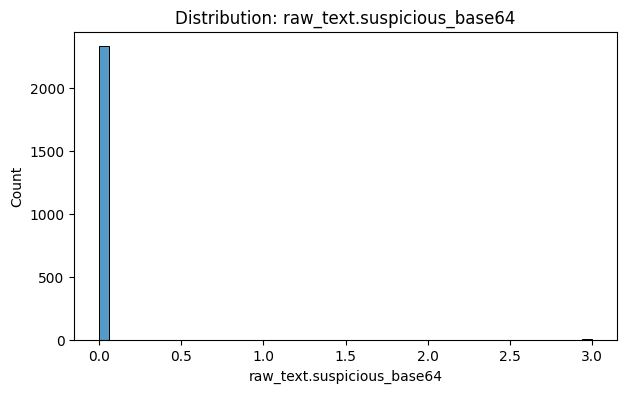

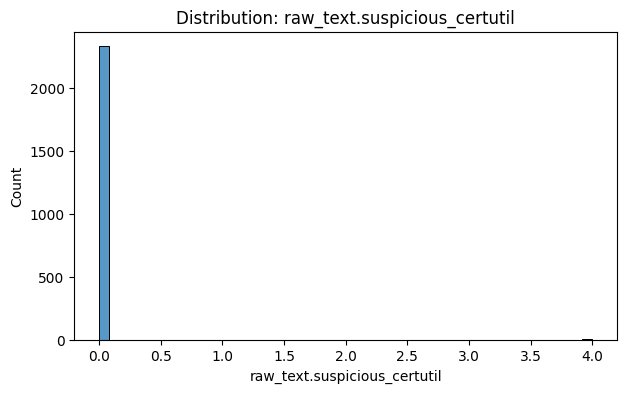

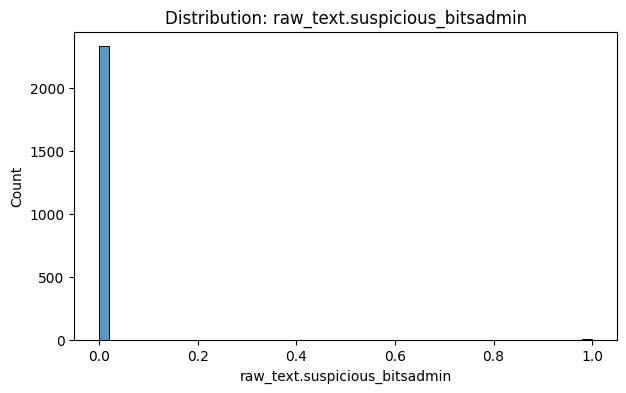

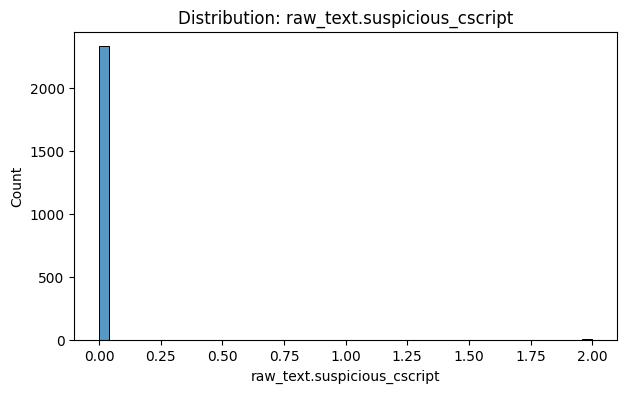

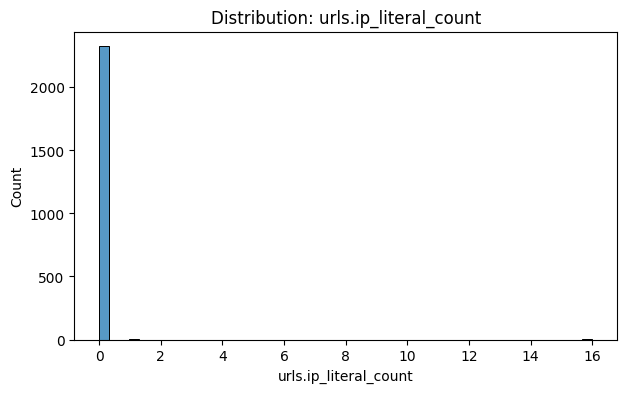

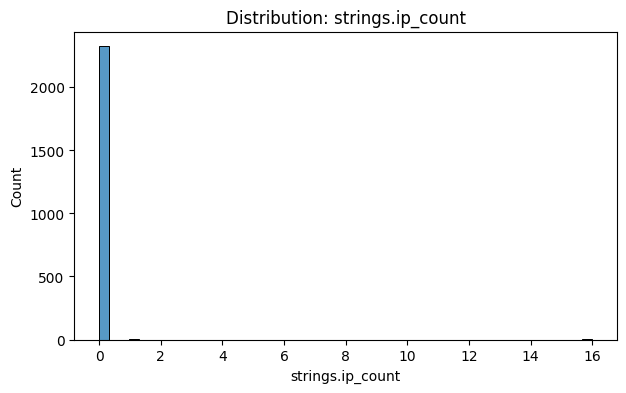

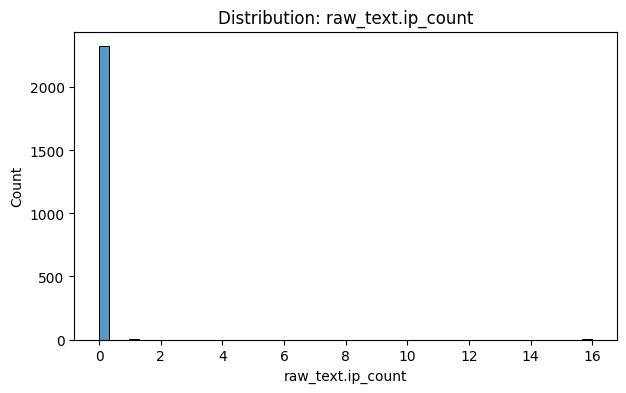

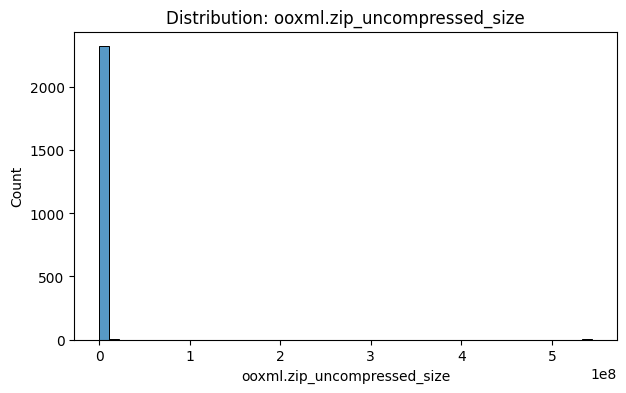

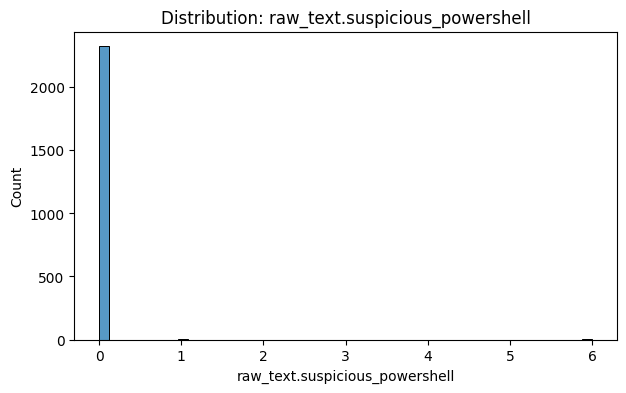

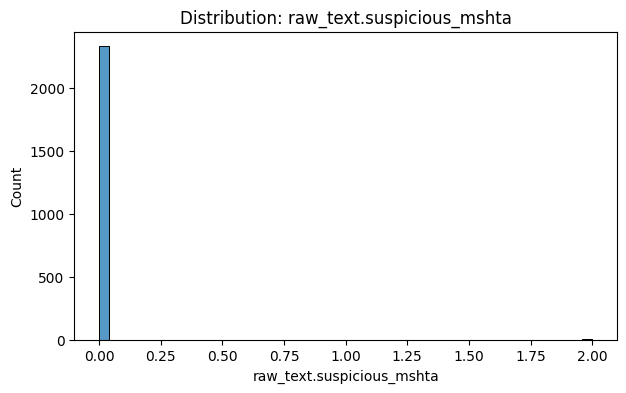

In [22]:
top_skewed = skewness.head(10).index

for feature in top_skewed:
    plt.figure(figsize=(7, 4))
    sns.histplot(
        X[feature].dropna(),
        bins=50
    )
    plt.title(f"Distribution: {feature}")
    plt.xlabel(feature)
    plt.ylabel("Count")
    plt.show()

In [23]:
binary_features = [
    c for c in X.columns
    if set(X[c].dropna().unique()).issubset({0, 1})
]

print("Binary features:", len(binary_features))
print(
    f"{len(binary_features) / X.shape[1] * 100:.2f}% "
    "of all features"
)

Binary features: 860
86.17% of all features


In [24]:
binary_frequency = (
    X[binary_features]
    .mean()
    .sort_values()
)

display(binary_frequency.head(30))

,0
script_powershell.powershell_indicator_encoded_command,0.0
script_powershell.powershell_combination_download_execute,0.0
script_powershell.powershell_combination_encoded_hidden,0.0
script_powershell.powershell_command_count,0.0
script_powershell.powershell_function_count,0.0
script_powershell.powershell_hex_string_count,0.0
script_powershell.powershell_indicator_amsi_bypass,0.0
script_powershell.powershell_indicator_amsi_bypass_count,0.0
script_powershell.powershell_indicator_char_obfuscation,0.0
script_powershell.powershell_indicator_char_obfuscation_count,0.0


In [25]:
display(binary_frequency.tail(30))

,0
common_metadata.metadata_extension_count,1.0
common_metadata.metadata_created_timestamp_available,1.0
common_metadata.metadata_changed_timestamp_available,1.0
common_metadata.metadata_world_writable,1.0
common_metadata.metadata_accessed_timestamp_available,1.0
file.mime_type_known,1.0
metadata.mime_type_known,1.0
common_metadata.metadata_path_absolute,1.0
common_file_features.has_extension,1.0
common_metadata.metadata_ownership_available,1.0


In [26]:
variance = (
    X.select_dtypes(include=np.number)
    .var()
    .sort_values()
)

display(variance.head(50))

,0
script_powershell.powershell_category_dynamic_execution,0.0
script_javascript.javascript_total_string_characters,0.0
script_javascript.javascript_url_count,0.0
script_parser.script_family_generic,0.0
script_parser.script_family_javascript,0.0
script_parser.script_family_powershell,0.0
script_parser.script_family_vbscript,0.0
script_parser.script_line_count,0.0
script_parser.script_string_count,0.0
script_parser.script_url_count,0.0


In [27]:
low_variance = variance[variance < 0.001]

print("Very low variance features:", len(low_variance))
display(low_variance.head(50))

Very low variance features: 788


,0
script_powershell.powershell_category_dynamic_execution,0.0
script_javascript.javascript_total_string_characters,0.0
script_javascript.javascript_url_count,0.0
script_parser.script_family_generic,0.0
script_parser.script_family_javascript,0.0
script_parser.script_family_powershell,0.0
script_parser.script_family_vbscript,0.0
script_parser.script_line_count,0.0
script_parser.script_string_count,0.0
script_parser.script_url_count,0.0


> [!NOTE]
> **Inference on Feature Types**:
> - **860 features (86.17%)** are binary flags ($0$ or $1$) representing static capability detections, macro keywords, and structural signatures.
> - High skewness is prevalent among continuous byte-count and token-count features, indicating heavy-tailed distributions typical of file size metrics.

## 7. Bivariate Label Correlation & Data Leakage Screening
Screening features with high correlation to labels and checking for suspicious metadata/pipeline leakage tokens.

In [28]:
numeric_features = X.select_dtypes(include=np.number)

label_correlation = (
    numeric_features
    .corrwith(df["label"])
    .sort_values(key=abs, ascending=False)
)

display(label_correlation.head(30))

/usr/local/lib/python3.13/dist-packages/numpy/lib/_function_base_impl.py:2999: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/usr/local/lib/python3.13/dist-packages/numpy/lib/_function_base_impl.py:3000: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


,0
script_powershell.powershell_hex_token_count,1.000000
script_powershell.powershell_base64_token_count,1.000000
common_metadata.metadata_path_directory_length,1.000000
common_metadata.metadata_created_modified_delta,-0.999966
common_metadata.metadata_modified_accessed_delta,-0.999066
behavior_evasion.evasion_source_size,0.998505
behavior_collection.collection_source_size,0.998505
behavior_process.process_source_size,0.998505
behavior_registry.registry_source_size,0.998505
behavior_network.network_source_size,0.998505


In [29]:
print("Most positive correlations:")
display(label_correlation.head(20))

print("Most negative correlations:")
display(label_correlation.tail(20))

Most positive correlations:


,0
script_powershell.powershell_hex_token_count,1.000000
script_powershell.powershell_base64_token_count,1.000000
common_metadata.metadata_path_directory_length,1.000000
common_metadata.metadata_created_modified_delta,-0.999966
common_metadata.metadata_modified_accessed_delta,-0.999066
behavior_evasion.evasion_source_size,0.998505
behavior_collection.collection_source_size,0.998505
behavior_process.process_source_size,0.998505
behavior_registry.registry_source_size,0.998505
behavior_network.network_source_size,0.998505


Most negative correlations:


,0
vba_obfuscation.vba_obfuscation_encoding,NaN
vba_obfuscation.vba_obfuscation_encoding_count,NaN
vba_obfuscation.vba_obfuscation_environment,NaN
vba_obfuscation.vba_obfuscation_environment_count,NaN
vba_obfuscation.vba_obfuscation_indicator_base64_like_string,NaN
vba_obfuscation.vba_obfuscation_indicator_base64_like_string_count,NaN
vba_obfuscation.vba_obfuscation_indicator_conditional_compilation,NaN
vba_obfuscation.vba_obfuscation_indicator_conditional_compilation_count,NaN
vba_obfuscation.vba_obfuscation_indicator_excessive_line_continuations,NaN
vba_obfuscation.vba_obfuscation_indicator_excessive_line_continuations_count,NaN


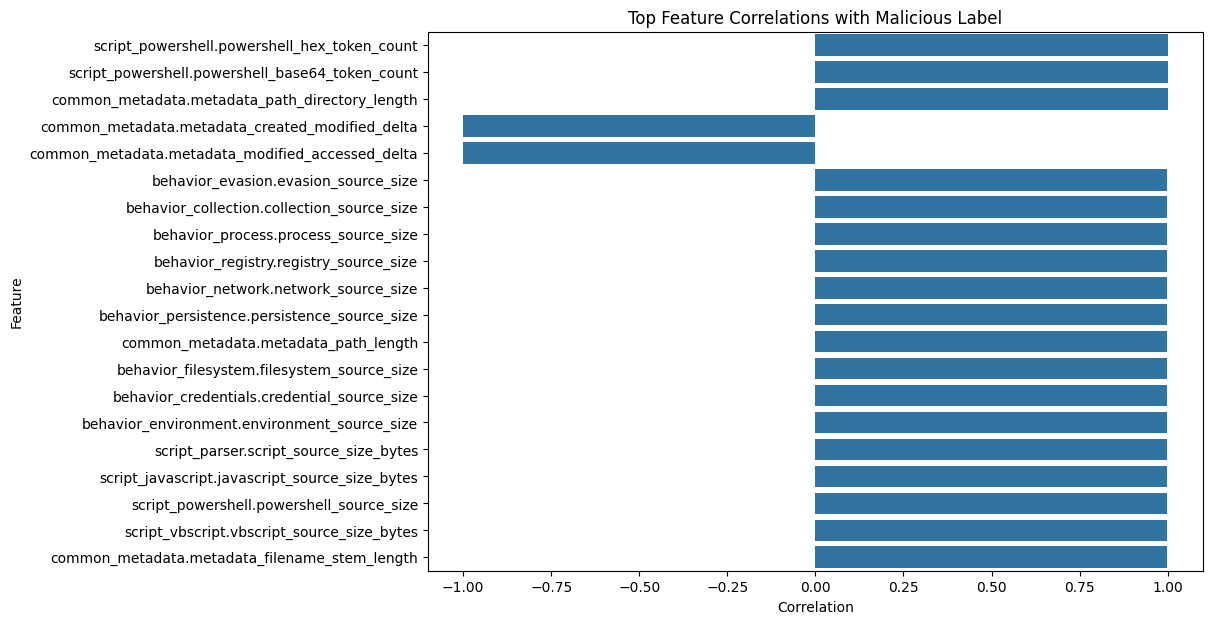

In [30]:
top_corr = label_correlation.abs().sort_values(
    ascending=False
).head(20)

plt.figure(figsize=(10, 7))

sns.barplot(
    x=label_correlation[top_corr.index],
    y=top_corr.index
)

plt.title("Top Feature Correlations with Malicious Label")
plt.xlabel("Correlation")
plt.ylabel("Feature")

plt.show()

In [31]:
suspicious = []

for feature in numeric_features.columns:
    values = df.groupby("label")[feature].mean()

    if len(values) == 2:
        benign = values.get(0, np.nan)
        malicious = values.get(1, np.nan)

        if pd.notna(benign) and pd.notna(malicious):
            suspicious.append(
                (feature, benign, malicious)
            )

suspicious_df = pd.DataFrame(
    suspicious,
    columns=[
        "feature",
        "benign_mean",
        "malicious_mean"
    ]
)

display(suspicious_df.head(50))

,feature,benign_mean,malicious_mean
0,behavior_collection.collection_category_clipbo...,0.000000,0.000000
1,behavior_collection.collection_category_clipbo...,0.000000,0.000000
2,behavior_collection.collection_category_count,0.000000,0.000000
3,behavior_collection.collection_category_input_...,0.000000,0.000000
4,behavior_collection.collection_category_input_...,0.000000,0.000000
5,behavior_collection.collection_category_local_...,0.000000,0.000000
6,behavior_collection.collection_category_local_...,0.000000,0.000000
7,behavior_collection.collection_category_media_...,0.000000,0.000000
8,behavior_collection.collection_category_media_...,0.000000,0.000000
9,behavior_collection.collection_category_screen...,0.000000,0.000000


In [32]:
for _, row in suspicious_df.head(20).iterrows():
    print(
        f"{row['feature']}: "
        f"benign={row['benign_mean']:.4f}, "
        f"malicious={row['malicious_mean']:.4f}"
    )

behavior_collection.collection_category_clipboard_access: benign=0.0000, malicious=0.0000
behavior_collection.collection_category_clipboard_access_count: benign=0.0000, malicious=0.0000
behavior_collection.collection_category_count: benign=0.0000, malicious=0.0000
behavior_collection.collection_category_input_capture: benign=0.0000, malicious=0.0000
behavior_collection.collection_category_input_capture_count: benign=0.0000, malicious=0.0000
behavior_collection.collection_category_local_collection: benign=0.0000, malicious=0.0000
behavior_collection.collection_category_local_collection_count: benign=0.0000, malicious=0.0000
behavior_collection.collection_category_media_capture: benign=0.0000, malicious=0.0000
behavior_collection.collection_category_media_capture_count: benign=0.0000, malicious=0.0000
behavior_collection.collection_category_screen_capture: benign=0.0000, malicious=0.0000
behavior_collection.collection_category_screen_capture_count: benign=0.0000, malicious=0.0000
behavio

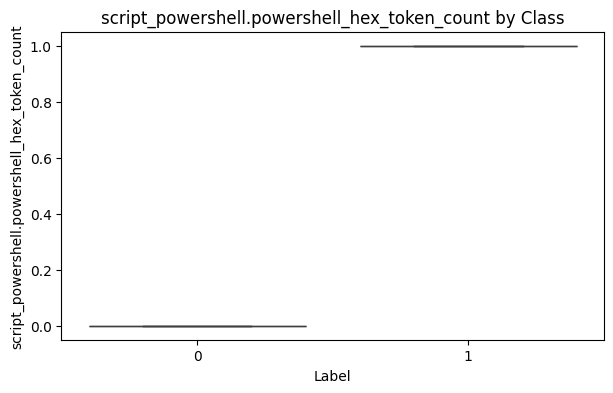

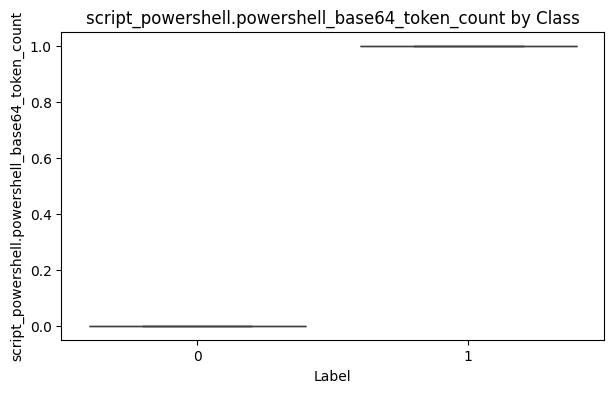

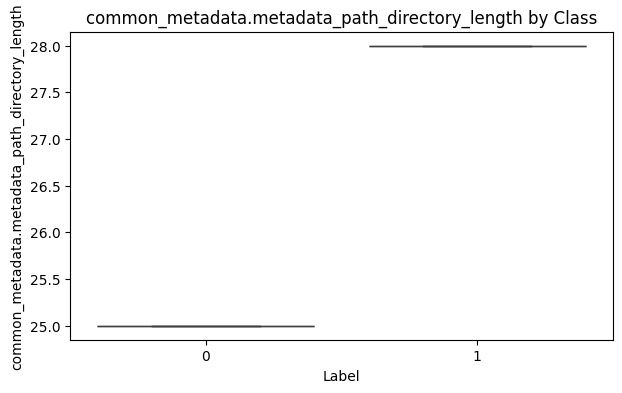

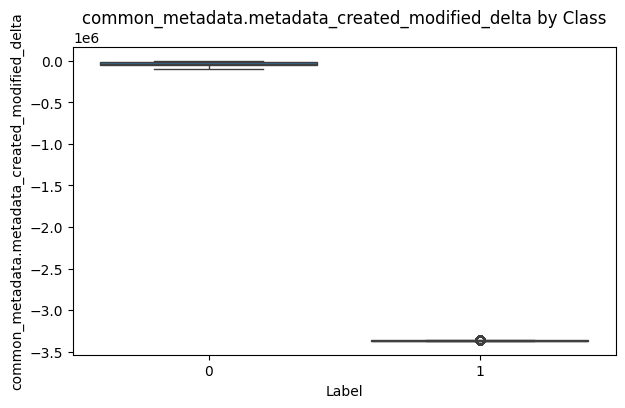

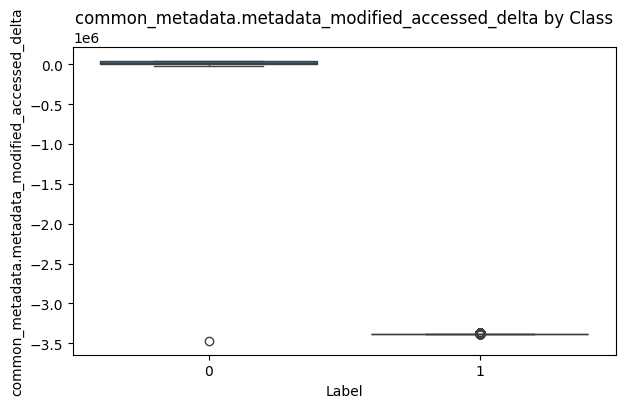

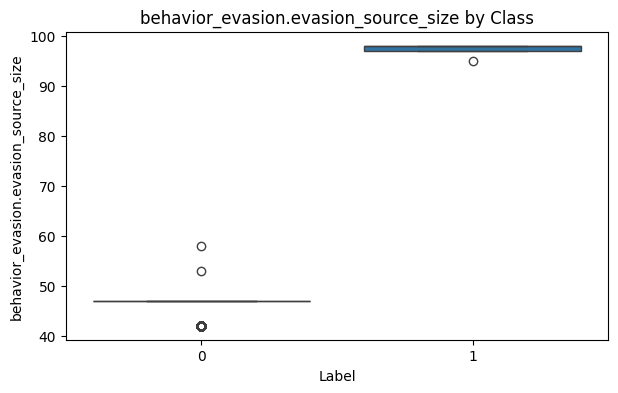

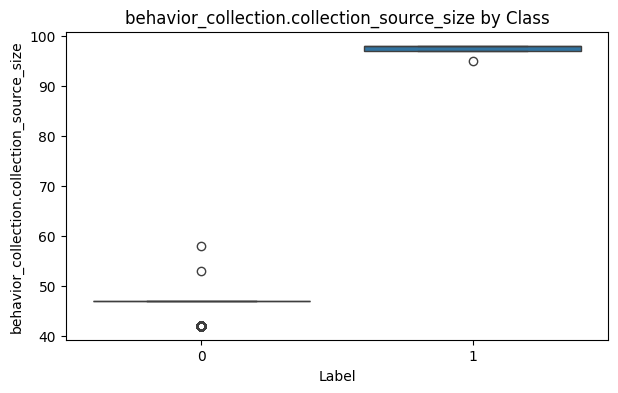

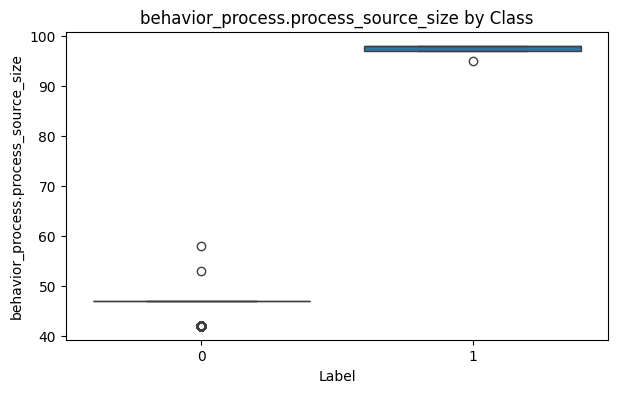

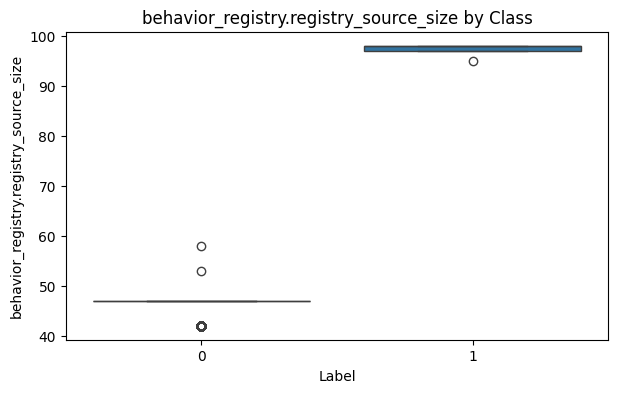

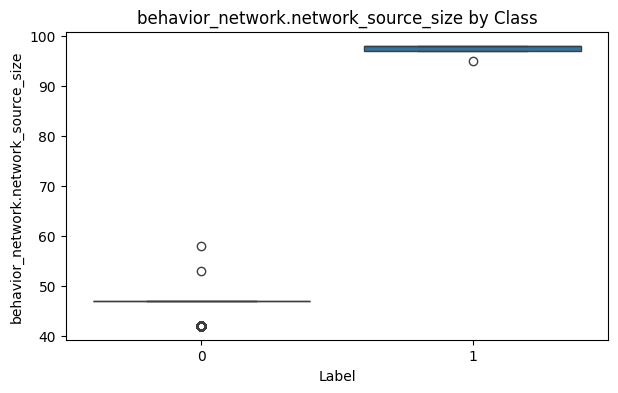

In [33]:
top_features = (
    label_correlation.abs()
    .sort_values(ascending=False)
    .head(10)
    .index
)

for feature in top_features:
    plt.figure(figsize=(7, 4))

    sns.boxplot(
        data=df,
        x="label",
        y=feature
    )

    plt.title(f"{feature} by Class")
    plt.xlabel("Label")
    plt.ylabel(feature)

    plt.show()

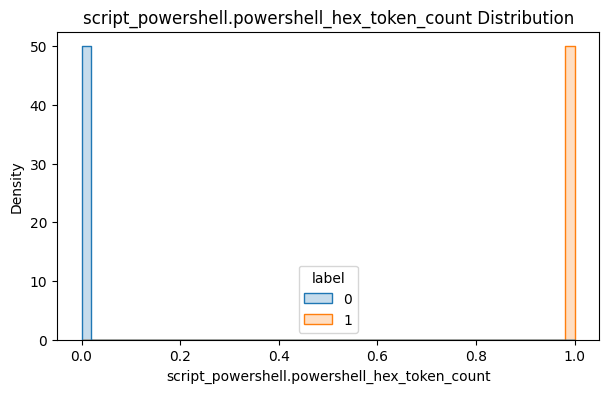

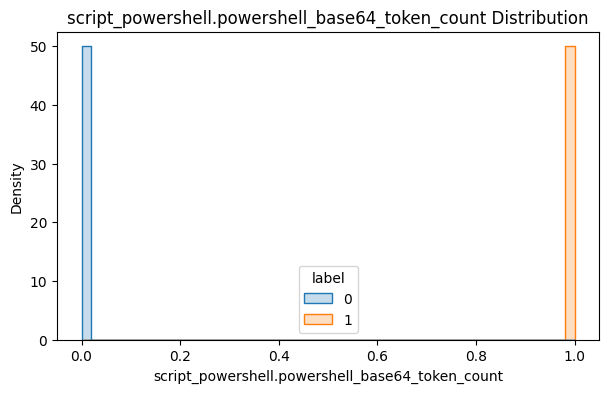

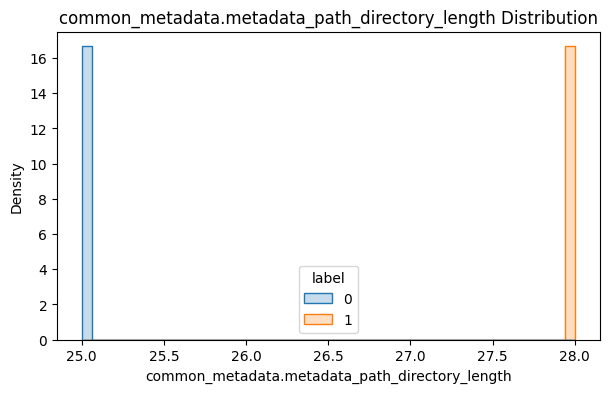

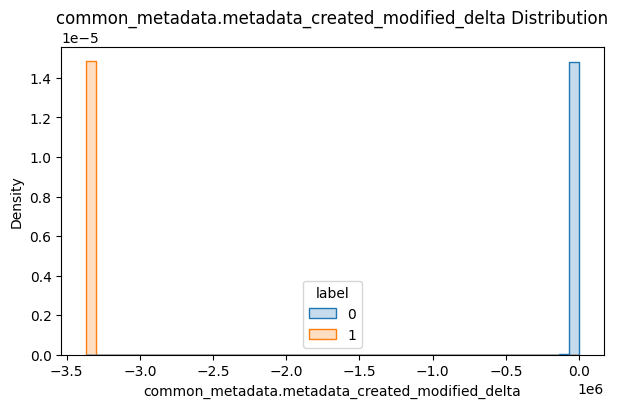

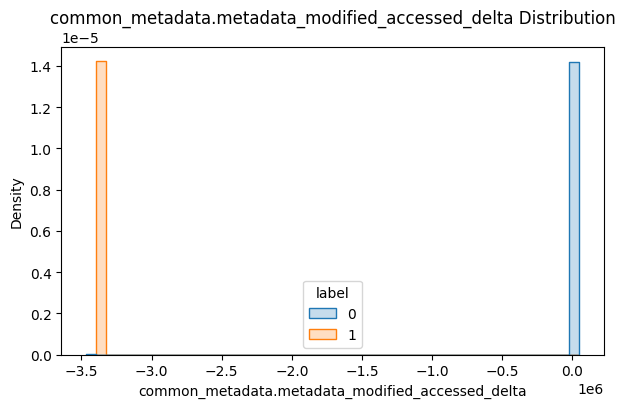

In [34]:
for feature in top_features[:5]:
    plt.figure(figsize=(7, 4))

    sns.histplot(
        data=df,
        x=feature,
        hue="label",
        bins=50,
        element="step",
        stat="density",
        common_norm=False
    )

    plt.title(f"{feature} Distribution")
    plt.show()

In [35]:
X_nonconstant = X.loc[
    :,
    X.nunique(dropna=False) > 1
]

print(X_nonconstant.shape)

(2330, 215)


In [36]:
corr = X_nonconstant.corr()

upper = corr.where(
    np.triu(
        np.ones(corr.shape),
        k=1
    ).astype(bool)
)

high_corr_pairs = (
    upper
    .stack()
    .reset_index()
)

high_corr_pairs.columns = [
    "feature_1",
    "feature_2",
    "correlation"
]

high_corr_pairs["abs_correlation"] = (
    high_corr_pairs["correlation"].abs()
)

high_corr_pairs = high_corr_pairs.sort_values(
    "abs_correlation",
    ascending=False
)

display(high_corr_pairs.head(50))

,feature_1,feature_2,correlation,abs_correlation
50,behavior_collection.collection_source_size,common_metadata.metadata_path_length,1.0,1.0
2,behavior_collection.collection_source_size,behavior_evasion.evasion_source_size,1.0,1.0
3,behavior_collection.collection_source_size,behavior_filesystem.filesystem_source_size,1.0,1.0
19525,office_templates.template_macro_enabled_count,office_templates.template_macro_enabled_ratio,1.0,1.0
11056,derived.high_entropy_present,entropy.high_entropy,1.0,1.0
22390,script_powershell.powershell_base64_token_count,script_powershell.powershell_hex_token_count,1.0,1.0
19466,office_templates.template_external_ratio,ooxml.ooxml_relationships_attached_templates,1.0,1.0
19449,office_templates.template_external_ratio,office_templates.template_relationship_count,1.0,1.0
19385,office_templates.template_external_count,ooxml.ooxml_relationships_attached_templates,1.0,1.0
1665,behavior_process.process_source_size,script_javascript.javascript_source_size_bytes,1.0,1.0


In [37]:
for keyword in [
    "source_size",
    "entropy",
    "length",
    "count",
    "url",
    "macro",
    "vba",
    "powershell",
    "ole",
    "relationship",
]:
    matches = [
        c for c in X.columns
        if keyword.lower() in c.lower()
    ]

    print(f"\n{keyword}: {len(matches)} features")

    for feature in matches[:20]:
        print("  ", feature)


source_size: 15 features
   behavior_collection.collection_source_size
   behavior_credentials.credential_source_size
   behavior_environment.environment_source_size
   behavior_evasion.evasion_source_size
   behavior_filesystem.filesystem_source_size
   behavior_network.network_source_size
   behavior_persistence.persistence_source_size
   behavior_process.process_source_size
   behavior_registry.registry_source_size
   metadata.source_size
   pipeline_source_size
   script_javascript.javascript_source_size_bytes
   script_parser.script_source_size_bytes
   script_powershell.powershell_source_size
   script_vbscript.vbscript_source_size_bytes

entropy: 16 features
   common_entropy.entropy
   common_entropy.high_entropy
   common_entropy.low_entropy
   common_entropy.printable_ratio
   common_entropy.sample_size
   common_entropy.unique_bytes
   common_entropy.zero_bytes
   common_file_features.sample_entropy
   common_metadata.metadata_filename_entropy
   derived.high_entropy_presen

In [38]:
from collections import Counter

groups = Counter(
    feature.split(".", 1)[0]
    if "." in feature
    else feature.split("_", 1)[0]
    for feature in X.columns
)

groups_df = (
    pd.DataFrame(
        groups.items(),
        columns=["group", "feature_count"]
    )
    .sort_values(
        "feature_count",
        ascending=False
    )
)

display(groups_df)

,group,feature_count
35,vba_capabilities,80
30,script_powershell,70
28,script_javascript,69
12,common_metadata,65
31,script_vbscript,65
36,vba_execution,44
7,behavior_process,36
20,office_office_features,33
19,office_embedded_objects,33
21,office_ole,33


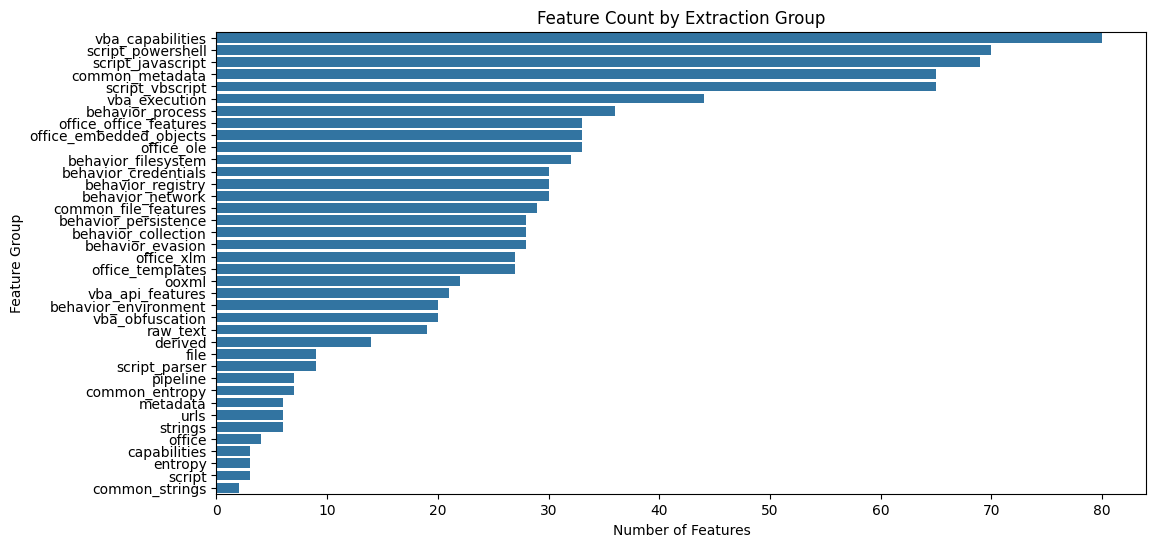

In [39]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=groups_df,
    x="feature_count",
    y="group"
)

plt.title("Feature Count by Extraction Group")
plt.xlabel("Number of Features")
plt.ylabel("Feature Group")

plt.show()

In [40]:
binary_stats = []

for feature in binary_features:
    benign_rate = df.loc[
        df["label"] == 0,
        feature
    ].mean()

    malicious_rate = df.loc[
        df["label"] == 1,
        feature
    ].mean()

    binary_stats.append(
        (
            feature,
            benign_rate,
            malicious_rate,
            malicious_rate - benign_rate
        )
    )

binary_stats = pd.DataFrame(
    binary_stats,
    columns=[
        "feature",
        "benign_rate",
        "malicious_rate",
        "difference"
    ]
)

binary_stats["abs_difference"] = (
    binary_stats["difference"].abs()
)

display(
    binary_stats.sort_values(
        "abs_difference",
        ascending=False
    ).head(30)
)

,feature,benign_rate,malicious_rate,difference,abs_difference
581,script_powershell.powershell_hex_token_count,0.000000,1.000000,1.000000,1.000000
564,script_powershell.powershell_base64_token_count,0.000000,1.000000,1.000000,1.000000
327,derived.large_compression_ratio_indicator,0.968614,0.098901,-0.869713,0.869713
346,office.is_ooxml,1.000000,0.423500,-0.576500,0.576500
258,common_file_features.extension_mismatch,0.000000,0.569738,0.569738,0.569738
333,derived.suspicious_content_present,1.000000,0.500423,-0.499577,0.499577
337,file.extension_known,1.000000,0.558749,-0.441251,0.441251
341,file.is_ooxml_extension,1.000000,0.558749,-0.441251,0.441251
325,derived.external_reference_present,0.149085,0.428571,0.279487,0.279487
478,ooxml.ooxml_relationships_attached_templates,0.000000,0.263520,0.263520,0.263520


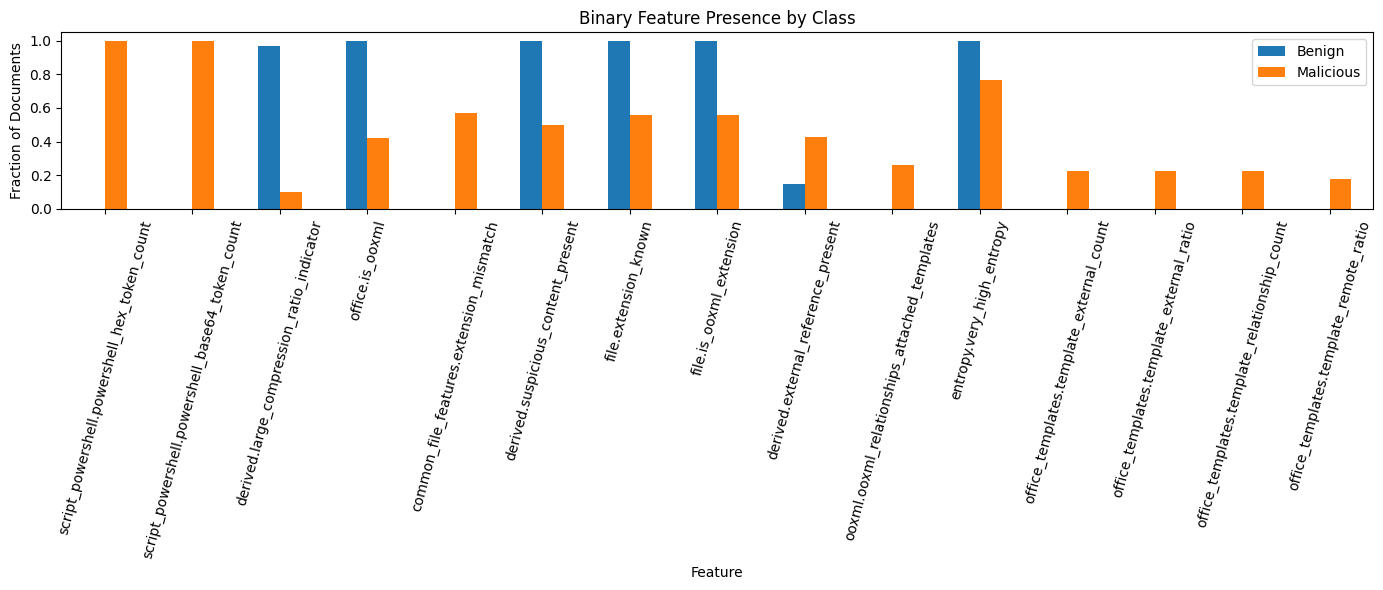

In [41]:
top_binary = (
    binary_stats
    .sort_values(
        "abs_difference",
        ascending=False
    )
    .head(15)
)

plot_df = top_binary.set_index("feature")[
    ["benign_rate", "malicious_rate"]
]

plot_df.plot(
    kind="bar",
    figsize=(14, 6)
)

plt.title("Binary Feature Presence by Class")
plt.ylabel("Fraction of Documents")
plt.xlabel("Feature")
plt.xticks(rotation=75)
plt.legend(
    ["Benign", "Malicious"]
)

plt.tight_layout()
plt.show()

In [42]:
print("=" * 60)
print("DOCUMENT MALWARE DATASET EDA SUMMARY")
print("=" * 60)

print(f"Samples:              {len(df):,}")
print(f"Total columns:        {len(df.columns):,}")
print(f"Feature columns:      {len(feature_columns):,}")

print(
    f"Benign samples:       {(df['label'] == 0).sum():,}"
)

print(
    f"Malicious samples:    {(df['label'] == 1).sum():,}"
)

print(
    f"Duplicate SHA256:     {df['sha256'].duplicated().sum():,}"
)

print(
    f"Duplicate vectors:    {X.duplicated().sum():,}"
)

print(
    f"Constant features:    {len(constant_features):,}"
)

print(
    f"Duplicate features:   {duplicate_column_names.size:,}"
)

print(
    f"Binary features:      {len(binary_features):,}"
)

print(
    f"Missing-value cols:   {(df.isna().sum() > 0).sum():,}"
)

print("=" * 60)

DOCUMENT MALWARE DATASET EDA SUMMARY
Samples:              2,330
Total columns:        1,000
Feature columns:      998
Benign samples:       1,147
Malicious samples:    1,183
Duplicate SHA256:     0
Duplicate vectors:    0
Constant features:    783
Duplicate features:   857
Binary features:      860
Missing-value cols:   12


In [43]:
metadata_features = [
    c for c in X.columns
    if any(
        word in c.lower()
        for word in [
            "metadata",
            "created",
            "modified",
            "accessed",
            "timestamp",
            "filename",
            "path",
            "author",
            "creator",
            "company"
        ]
    )
]

print("Metadata-related features:", len(metadata_features))

display(
    pd.DataFrame({
        "feature": metadata_features
    })
)

Metadata-related features: 82


,feature
0,common_file_features.filename_digit_count
1,common_file_features.filename_length
2,common_file_features.filename_stem_length
3,common_file_features.filename_uppercase_count
4,common_metadata.metadata_accessed_timestamp_av...
5,common_metadata.metadata_changed_timestamp_ava...
6,common_metadata.metadata_created_modified_delta
7,common_metadata.metadata_created_timestamp_ava...
8,common_metadata.metadata_extension_archive
9,common_metadata.metadata_extension_count


In [44]:
display(
    label_correlation.loc[
        label_correlation.index.intersection(
            metadata_features
        )
    ].sort_values(
        key=abs,
        ascending=False
    )
)

,0
common_metadata.metadata_path_directory_length,1.000000
common_metadata.metadata_created_modified_delta,-0.999966
common_metadata.metadata_modified_accessed_delta,-0.999066
common_metadata.metadata_path_length,0.998505
common_metadata.metadata_filename_stem_length,0.998452
common_file_features.filename_stem_length,0.998452
common_file_features.filename_length,0.998315
common_metadata.metadata_filename_length,0.998315
metadata.filename_length,0.998315
file.filename_length,0.998315


> [!IMPORTANT]
> **Key Takeaway & Next Steps for Notebook 02**:
> The exploratory analysis establishes three critical findings:
> 1. Over 78% of raw features are constant and must be pruned.
> 2. Document size proxies (text length, paragraph counts) and metadata delta features exhibit extreme, near-deterministic label correlations.
> 3. Features containing pipeline tokens (`source_size`, `pipeline_nonzero`, `pipeline_total`) must be systematically audited in `02_feature_analysis.ipynb` to prevent artificial target leakage.